## assignment 5: autoencoder

In [1]:
#same dataset
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms

# 1. Setup random seed
torch.manual_seed(42)

# 2. Download and prepare the professional MNIST dataset
# This automatically scales the pixel values between 0.0 and 1.0!
transform = transforms.Compose([transforms.ToTensor()])

train_dataset = torchvision.datasets.MNIST(root='./data', train=True, download=True, transform=transform)
test_dataset = torchvision.datasets.MNIST(root='./data', train=False, download=True, transform=transform)

# 3. Create the DataLoader factories (Chops data into mini-batches of 64 images)
train_loader = torch.utils.data.DataLoader(dataset=train_dataset, batch_size=64, shuffle=True)
test_loader = torch.utils.data.DataLoader(dataset=test_dataset, batch_size=64, shuffle=False)


100%|██████████| 9.91M/9.91M [00:00<00:00, 15.8MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 480kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 4.42MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 5.05MB/s]


In [2]:
import torch
import torch.nn as nn

class Encoder(nn.Module):
    def __init__(self):
        super().__init__()
        self.l1 = nn.Sequential(
            nn.Linear(784, 64), # compress to hidden dim
            nn.ReLU(), # activate to "spline" it (it, as in the multiple Wx + b's)
            nn.Linear(64,2) #linear proj. from 64-big-vector to 2 latent coordinates/2-dim vector
        )
    def forward(self, x):
        return self.l1(x)

class Decoder(nn.Module):
    def __init__(self):
        super().__init__()
        self.l1 = nn.Sequential(
            nn.Linear(2, 64), #decompress/project upwards to 64
            nn.ReLU(), #re-active/re-spline
            nn.Linear(64, 784), #back to 784-pixel-space
            nn.Sigmoid(), #ensure outputs within range [0,1] where 0 is black pixels and 1 is white pixels
        )
    def forward(self, z):
        return self.l1(z)

class Autoencoder(nn.Module):
    def __init__(self):
        super().__init__()
        self.encoder = Encoder()
        self.decoder = Decoder()
    def forward(self, x):
        z = self.encoder(x)
        y_hat = self.decoder(z)
        return y_hat

model = Autoencoder()

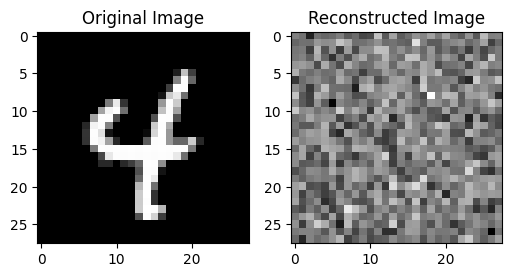

Epoch 1 | Average Loss: 0.1741


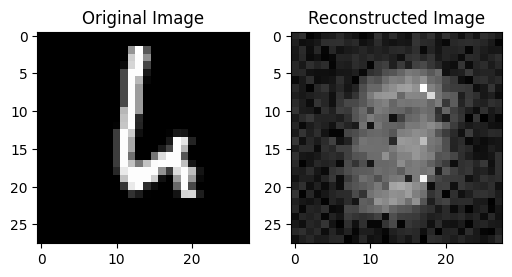

Epoch 2 | Average Loss: 0.0721


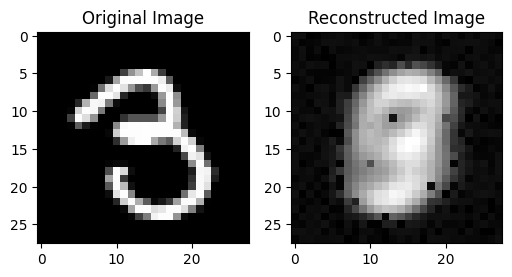

Epoch 3 | Average Loss: 0.0696


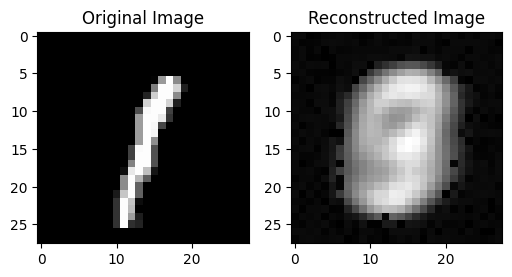

Epoch 4 | Average Loss: 0.0689


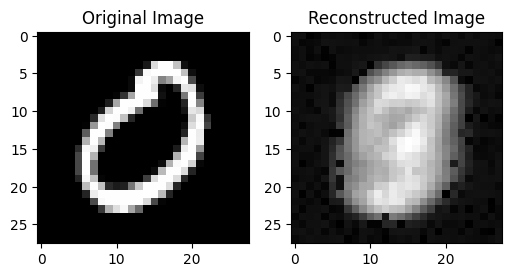

Epoch 5 | Average Loss: 0.0684


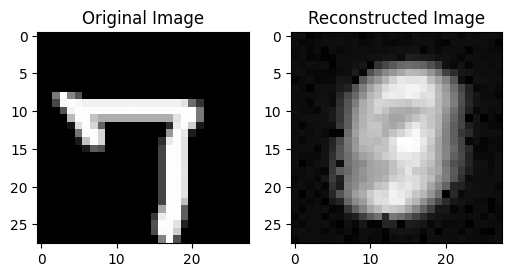

Epoch 6 | Average Loss: 0.0680


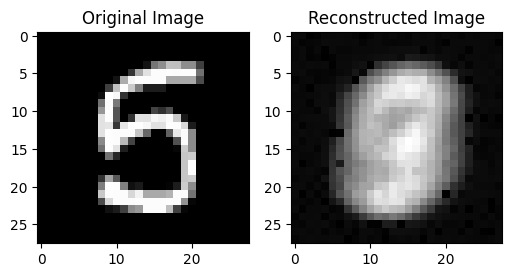

Epoch 7 | Average Loss: 0.0677


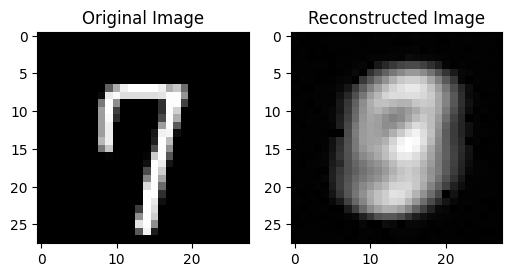

Epoch 8 | Average Loss: 0.0674


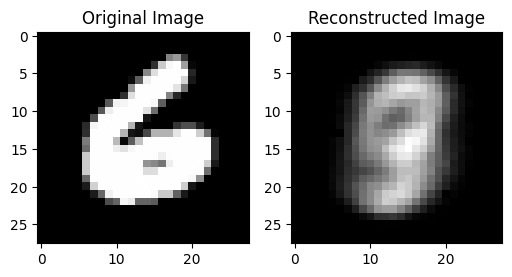

Epoch 9 | Average Loss: 0.0672


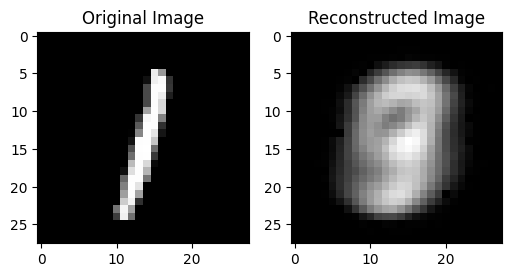

Epoch 10 | Average Loss: 0.0669


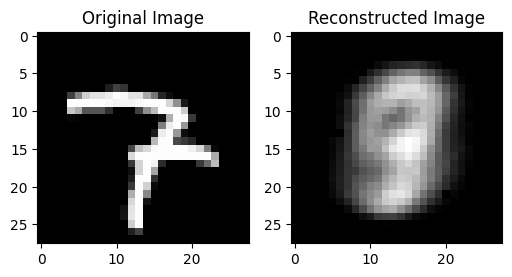

Epoch 11 | Average Loss: 0.0667


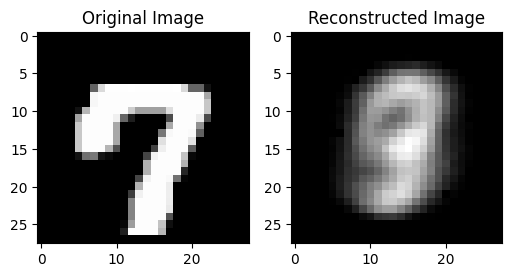

Epoch 12 | Average Loss: 0.0664


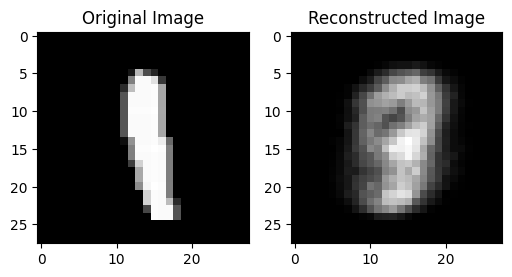

Epoch 13 | Average Loss: 0.0661


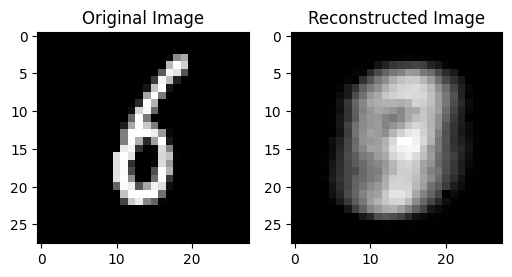

Epoch 14 | Average Loss: 0.0657


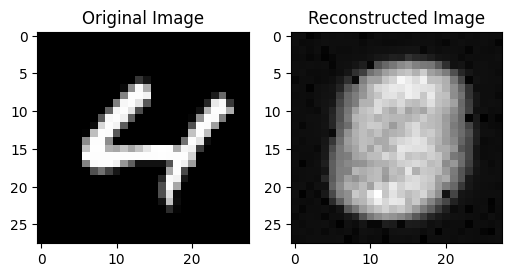

Epoch 15 | Average Loss: 0.0653


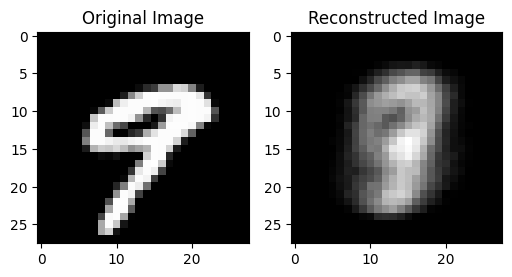

Epoch 16 | Average Loss: 0.0648


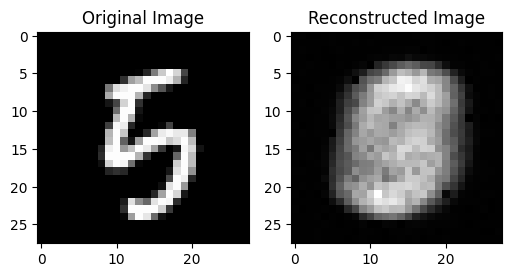

Epoch 17 | Average Loss: 0.0643


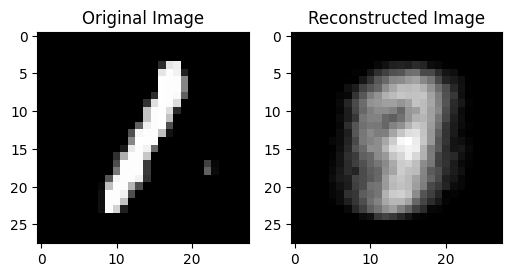

Epoch 18 | Average Loss: 0.0638


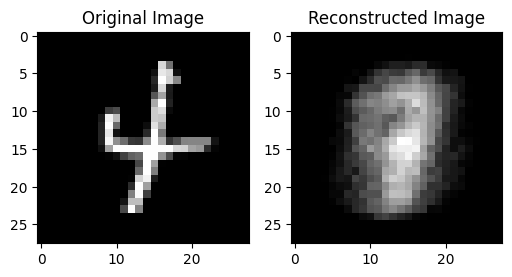

Epoch 19 | Average Loss: 0.0633


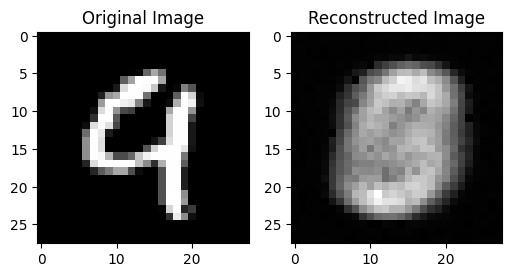

Epoch 20 | Average Loss: 0.0629


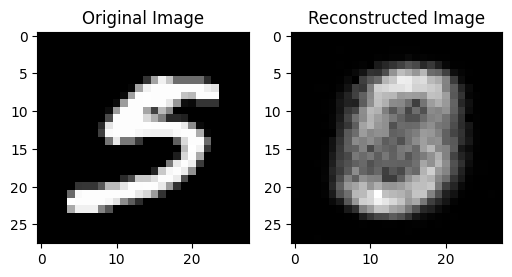

Epoch 21 | Average Loss: 0.0625


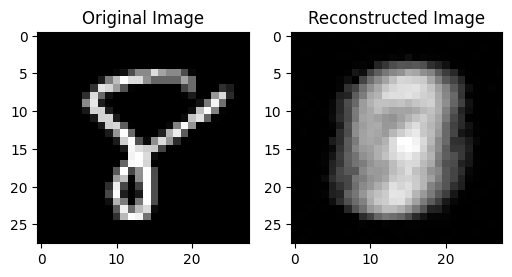

Epoch 22 | Average Loss: 0.0622


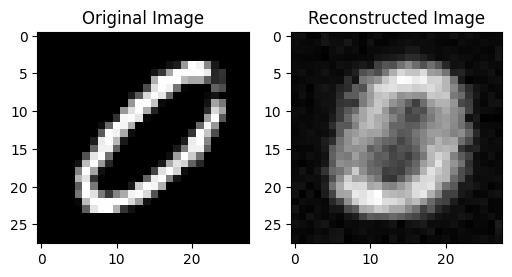

Epoch 23 | Average Loss: 0.0619


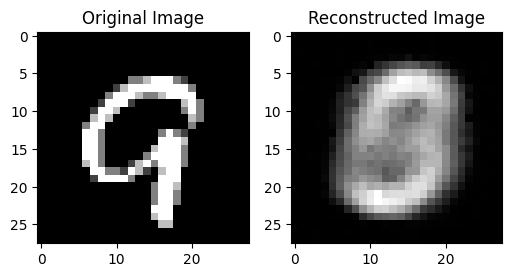

Epoch 24 | Average Loss: 0.0616


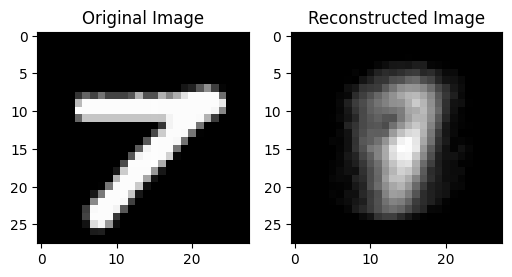

Epoch 25 | Average Loss: 0.0614


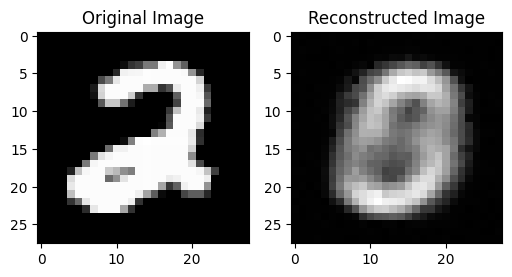

Epoch 26 | Average Loss: 0.0612


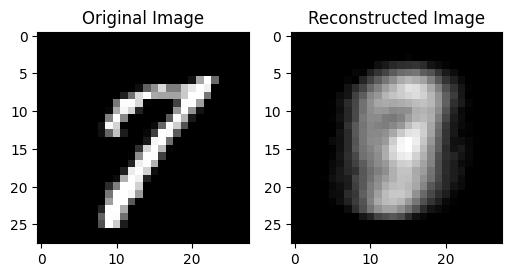

KeyboardInterrupt: 

In [14]:
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision.transforms import v2
import matplotlib.pyplot as plt


optimizer = optim.SGD(lr=1e-1, params=model.parameters())
criterion = nn.MSELoss()

def train(epochs=100):
    for epoch in range(epochs):
        total_loss = 0
        for batch_idx, (inputs, targets) in enumerate(train_loader):
            optimizer.zero_grad()
            flattened = inputs.view(inputs.size(0),-1)
            preds = model(flattened)
            loss = criterion(preds,flattened) #compute loss from predicted versus original flattened img
            loss.backward()
            optimizer.step()
            total_loss += loss.item()
            if batch_idx == 0: #every 1st sub-batch/batch
                model.eval() #eval mode real quick
                with torch.no_grad():
                    orig_img = flattened.reshape(64,28,28).numpy()[0]
                    reconstructed = preds.reshape(64,28,28).numpy()[0]
                    fig, axes = plt.subplots(1,2,figsize=(6,3))
                    axes[0].imshow(orig_img,cmap="gray")
                    axes[0].set_title("Original Image")
                    axes[1].imshow(reconstructed,cmap="gray")
                    axes[1].set_title("Reconstructed Image")
                    plt.show()
                    plt.close(fig)
                model.train() #back to training
        avg_loss = total_loss / len(train_loader)
        print(f"Epoch {epoch+1} | Average Loss: {avg_loss:.4f}")

train()
        